# 03 · Manavgat 2021: burn severity and five years of recovery

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/oechenique/remote_sensing/blob/main/notebooks/03_manavgat_burn_ndvi.ipynb)

On **28 July 2021** a wildfire started near Manavgat, 60 km east of Antalya, and burned through pine forest on the southern slopes of the Taurus Mountains for over a week. This notebook measures it from Sentinel-2 alone:

1. **Burn severity** with the differenced Normalized Burn Ratio (**dNBR**) from cloud-free composites before and after the fire, classified with the USGS thresholds, in hectares.
2. **Recovery**: a 2019–2026 NDVI time series of the severely burned area against an unburned forest control.

Everything runs on a CPU (a few minutes on a laptop or free Colab).

**Data:** Contains modified Copernicus Sentinel data 2019–2026, via the [Earth Search](https://earth-search.aws.element84.com/v1) STAC API (Element 84).

## Setup

In [1]:
# Colab already ships numpy, pandas, xarray, dask and matplotlib; install only what is missing.
# Locally, use requirements.txt instead.
import sys

if "google.colab" in sys.modules:
    %pip install -q rasterio==1.5.2 pystac-client==0.9.1 odc-stac==0.5.3 spyndex==0.12.0

In [2]:
import time
import warnings
from pathlib import Path

import dask
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spyndex
import xarray as xr
from odc.stac import configure_rio, load
from pystac_client import Client

warnings.filterwarnings("ignore", message="Could not parse bucket")
# rasterio's NotGeoreferencedWarning shows up intermittently while odc-stac reprojects;
# runs with and without it gave identical results
warnings.filterwarnings("ignore", category=UserWarning, module="rasterio.warp")
configure_rio(cloud_defaults=True)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG_DIR = ROOT / "docs" / "img"
IMG_DIR.mkdir(parents=True, exist_ok=True)
T0 = time.time()

In [3]:
EARTH_SEARCH = "https://earth-search.aws.element84.com/v1"
C1 = "sentinel-2-c1-l2a"  # Collection 1: whole archive reprocessed with baselines 05.xx
BBOX = [31.24, 36.76, 31.78, 37.09]  # Manavgat district, Antalya province
CRS = "EPSG:32636"  # UTM 36N

FIRE_START = pd.Timestamp("2021-07-28")
PRE_FIRE = "2021-06-15/2021-07-25"
POST_FIRE = "2021-08-20/2021-09-30"

# SCL classes treated as invalid: no data, saturated, cloud shadow, water, clouds, cirrus, snow
# (winter snow on the Taurus drags NDVI down in both areas)
SCL_DROP = [0, 1, 3, 6, 8, 9, 10, 11]

catalog = Client.open(EARTH_SEARCH)


def search(datetime, collection=C1, max_cloud=30):
    return catalog.search(
        collections=[collection], bbox=BBOX, datetime=datetime, query={"eo:cloud_cover": {"lt": max_cloud}}
    ).item_collection()


def load_reflectance(items, bands, resolution, offset=None):
    """Lazy, cloud-masked surface reflectance on a UTM grid, one step per acquisition day.

    Scale and offset come from the assets' raster:bands metadata unless `offset` is given.
    """
    ds = load(items, bands=bands + ["scl"], bbox=BBOX, crs=CRS, resolution=resolution,
              groupby="solar_day", chunks={"x": 2048, "y": 2048})
    raster_band = items[0].assets[bands[0]].extra_fields["raster:bands"][0]
    if offset is None:
        offset = raster_band["offset"]
    dn = ds[bands]
    refl = dn.where(~ds.scl.isin(SCL_DROP) & (dn > 0)) * raster_band["scale"] + offset
    return refl.where(refl > 0)


def index(name, d):
    """Spectral index from the Awesome Spectral Indices catalog."""
    params = {"N": d.nir, "R": d.red} if name == "NDVI" else {"N": d.nir, "S2": d.swir22}
    return spyndex.computeIndex(name, params=params)

## 1 · Burn severity (dNBR)

$NBR = \frac{NIR - SWIR_2}{NIR + SWIR_2}$ drops sharply when vegetation burns: healthy leaves reflect NIR, charcoal and bare soil reflect SWIR. **dNBR = NBR<sub>pre</sub> − NBR<sub>post</sub>**, from the median of every clear observation in each window, at 20 m (SWIR<sub>2</sub>'s native resolution).

In [4]:
pre_items, post_items = search(PRE_FIRE), search(POST_FIRE)
print(f"pre-fire: {len(pre_items)} scenes · post-fire: {len(post_items)} scenes")

BANDS = ["red", "nir", "swir22"]
pre, post = dask.compute(
    load_reflectance(pre_items, BANDS, 20).median("time"),
    load_reflectance(post_items, BANDS, 20).median("time"),
)
ndvi_pre = index("NDVI", pre)
# Only pixels that were vegetated before the fire: leaves out sea, bare rock and towns
dnbr = (index("NBR", pre) - index("NBR", post)).where(ndvi_pre > 0.2)
print(f"{dict(dnbr.sizes)} px at 20 m · {time.time() - T0:.0f} s so far")

pre-fire: 17 scenes · post-fire: 14 scenes


{'y': 1869, 'x': 2434} px at 20 m · 35 s so far


Severity classes from Key & Benson (2006), *Landscape Assessment*, FIREMON / USGS. Each 20 m pixel is 0.04 ha.

In [5]:
SEVERITY = pd.DataFrame(
    {
        "class": ["Unburned", "Low", "Moderate-low", "Moderate-high", "High"],
        "dnbr_from": [-np.inf, 0.10, 0.27, 0.44, 0.66],
        "color": ["#e8e8e0", "#fff70b", "#ffaf38", "#ff641b", "#a41fd6"],
    }
)
PIXEL_HA = 20 * 20 / 10_000

severity = xr.where(dnbr.notnull(), np.digitize(dnbr.fillna(-1), SEVERITY.dnbr_from[1:]), -1)
counts = np.bincount(severity.values[severity.values >= 0].ravel(), minlength=len(SEVERITY))
SEVERITY["hectares"] = (counts * PIXEL_HA).round(-1).astype(int)
burned = SEVERITY.iloc[1:]
print(f"burned (dNBR ≥ 0.10): {burned.hectares.sum():,} ha · moderate-high or high (dNBR ≥ 0.44): {burned.hectares.iloc[2:].sum():,} ha")
SEVERITY[["class", "dnbr_from", "hectares"]]

burned (dNBR ≥ 0.10): 50,030 ha · moderate-high or high (dNBR ≥ 0.44): 22,300 ha


,class,dnbr_from,hectares
0,Unburned,-inf,106810
1,Low,0.10,14970
2,Moderate-low,0.27,12760
3,Moderate-high,0.44,10290
4,High,0.66,12010


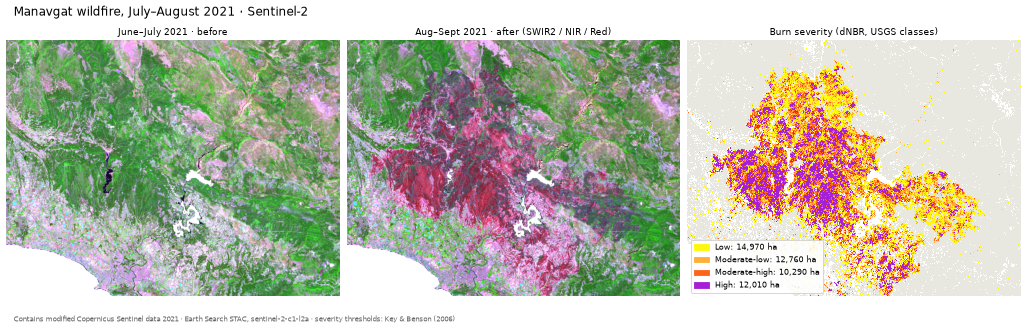

In [6]:
def false_color(d, vmax=(0.35, 0.45, 0.20)):
    """SWIR2 / NIR / Red: burned ground shows red-brown, live vegetation green."""
    stack = np.dstack([d.swir22.values / vmax[0], d.nir.values / vmax[1], d.red.values / vmax[2]])
    return np.clip(np.nan_to_num(stack, nan=1.0), 0, 1)


extent = [dnbr.x.min().item(), dnbr.x.max().item(), dnbr.y.min().item(), dnbr.y.max().item()]
sev_cmap = mpl.colors.ListedColormap(SEVERITY.color)
sev_cmap.set_under("white")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), constrained_layout=True)
axes[0].imshow(false_color(pre), extent=extent)
axes[0].set_title("June–July 2021 · before", fontsize=11)
axes[1].imshow(false_color(post), extent=extent)
axes[1].set_title("Aug–Sept 2021 · after (SWIR2 / NIR / Red)", fontsize=11)
axes[2].imshow(severity.where(severity >= 0, -1), cmap=sev_cmap, vmin=-0.5, vmax=len(SEVERITY) - 0.5,
               extent=extent, interpolation="nearest")
axes[2].set_title("Burn severity (dNBR, USGS classes)", fontsize=11)
handles = [mpl.patches.Patch(color=r.color, label=f"{r['class']}: {r.hectares:,} ha") for _, r in SEVERITY.iloc[1:].iterrows()]
axes[2].legend(handles=handles, loc="lower left", fontsize=9, framealpha=0.9)
for ax in axes:
    ax.set_axis_off()
fig.suptitle("Manavgat wildfire, July–August 2021 · Sentinel-2", fontsize=14, x=0.01, ha="left")
fig.text(0.01, -0.02, "Contains modified Copernicus Sentinel data 2021 · Earth Search STAC, sentinel-2-c1-l2a · severity thresholds: Key & Benson (2006)", fontsize=8, color="0.4")
fig.savefig(IMG_DIR / "manavgat_severity.png", dpi=130, bbox_inches="tight")
fig.set_dpi(60)
plt.show()

## 2 · Recovery: NDVI 2019–2026

### A gap in Collection 1
Over this area `sentinel-2-c1-l2a` has only a handful of scenes between January and November 2022 (10 for the whole year, against ~170 in the older collection), right in the first year of recovery. The gap is filled from the older `sentinel-2-l2a` collection, with scenes processed with baseline 04.00 or later (the same L2A processor generation as Collection 1).

**One trap:** since baseline 04.00 (25 January 2022) ESA adds +1000 to every L2A digital number, and Collection 1 keeps that convention: reflectance = DN × 0.0001 − 0.1. Earth Search's older `sentinel-2-l2a` COGs, though, **already have those 1000 subtracted**, while their `raster:bands` metadata still says `offset: -0.1`. Comparing the same scene in both collections (every 2022 date available in both, both MGRS tiles) the DNs differ by 995–1042. Following the metadata would subtract the offset twice: dense forest drops to zero reflectance and NDVI is inflated. For these scenes the notebook uses reflectance = DN × 0.0001.

In [7]:
TS_RANGE = "2019-01-01/2026-09-30"
GAP = (pd.Timestamp("2022-01-01"), pd.Timestamp("2022-11-30 23:59:59"))

c1_items = [i for i in search(TS_RANGE, max_cloud=20) if not GAP[0] <= pd.Timestamp(i.datetime).tz_localize(None) <= GAP[1]]
gap_items = [
    i for i in search(f"{GAP[0]:%Y-%m-%d}/{GAP[1]:%Y-%m-%d}", collection="sentinel-2-l2a", max_cloud=20)
    if i.properties["s2:processing_baseline"] >= "04.00"
]
print(f"{len(c1_items)} scenes from {C1} + {len(gap_items)} from sentinel-2-l2a (2022, baseline ≥ 04.00)")

630 scenes from sentinel-2-c1-l2a + 92 from sentinel-2-l2a (2022, baseline ≥ 04.00)


The time series runs at 60 m: plenty for averages over thousands of hectares, and it reads the COGs' overviews, so ~700 scenes take a couple of minutes.

- **Burned:** pixels with dNBR ≥ 0.44 (moderate-high and high severity).
- **Control:** unburned (dNBR < 0.10) pixels that were dense vegetation before the fire (NDVI > 0.5). It absorbs seasonality and drought years, so the **ratio burned / control** isolates the fire.

In [8]:
TS_RES = 60
pre60, post60 = dask.compute(
    load_reflectance(pre_items, BANDS, TS_RES).median("time"),
    load_reflectance(post_items, BANDS, TS_RES).median("time"),
)
dnbr60 = index("NBR", pre60) - index("NBR", post60)
ndvi_pre60 = index("NDVI", pre60)
burn_mask = (dnbr60 >= 0.44) & (ndvi_pre60 > 0.2)
control_mask = (dnbr60 < 0.10) & (ndvi_pre60 > 0.5)
print(f"burned: {int(burn_mask.sum()):,} px · control: {int(control_mask.sum()):,} px (60 m)")

ts = xr.concat(
    [
        load_reflectance(c1_items, ["red", "nir"], TS_RES),
        load_reflectance(gap_items, ["red", "nir"], TS_RES, offset=0.0),  # already harmonized, see above
    ],
    dim="time",
).sortby("time")
ndvi = index("NDVI", ts)
ndvi = ndvi.where((ts.nir + ts.red > 0.02) & (abs(ndvi) <= 1))

stats = dask.compute(
    ndvi.where(burn_mask).mean(["x", "y"]),
    ndvi.where(control_mask).mean(["x", "y"]),
    ndvi.where(burn_mask).count(["x", "y"]) / burn_mask.sum(),
    ndvi.where(control_mask).count(["x", "y"]) / control_mask.sum(),
)
df = pd.DataFrame(
    {name: s.values for name, s in zip(["burned", "control", "burned_cov", "control_cov"], stats)},
    index=pd.DatetimeIndex(ts.time.values).normalize(),
)
# Keep only acquisitions where both areas are at least 80 % cloud-free
df = df[(df.burned_cov >= 0.8) & (df.control_cov >= 0.8)].drop(columns=["burned_cov", "control_cov"])
df["ratio"] = df.burned / df.control
print(f"{len(df)} usable acquisitions · {time.time() - T0:.0f} s so far")

burned: 60,835 px · control: 143,833 px (60 m)


258 usable acquisitions · 273 s so far


In [9]:
summer = df[df.index.month.isin([6, 7, 8, 9])]
before = summer[summer.index < FIRE_START]
after = summer[summer.index >= FIRE_START]
by_summer = after.groupby(after.index.year)[["burned", "control", "ratio"]].median()
by_summer.loc["2019–2021 (pre-fire)"] = before[["burned", "control", "ratio"]].median()
by_summer = by_summer.iloc[[-1, *range(len(by_summer) - 1)]]

pre_ratio, fire_ratio, last_ratio = by_summer.ratio.iloc[0], by_summer.ratio.iloc[1], by_summer.ratio.iloc[-1]
by_summer["recovered_%"] = ((by_summer.ratio - fire_ratio) / (pre_ratio - fire_ratio) * 100).round()
by_summer.loc["2019–2021 (pre-fire)", "recovered_%"] = np.nan
print(f"summer NDVI, burned area: {by_summer.burned.iloc[0]:.2f} before → {by_summer.burned.iloc[1]:.2f} after the fire → {by_summer.burned.iloc[-1]:.2f} in {by_summer.index[-1]}")
print(f"relative to the control: {pre_ratio:.0%} → {fire_ratio:.0%} → {last_ratio:.0%} ({by_summer['recovered_%'].iloc[-1]:.0f} % of the gap closed)")
by_summer.round(2)

summer NDVI, burned area: 0.67 before → 0.21 after the fire → 0.49 in 2026
relative to the control: 102% → 32% → 73% (60 % of the gap closed)


,burned,control,ratio,recovered_%
2019–2021 (pre-fire),0.67,0.66,1.02,NaN
2021,0.21,0.66,0.32,0.0
2022,0.25,0.64,0.39,10.0
2023,0.37,0.65,0.56,35.0
2024,0.39,0.65,0.59,39.0
2025,0.43,0.66,0.66,49.0
2026,0.49,0.67,0.73,60.0


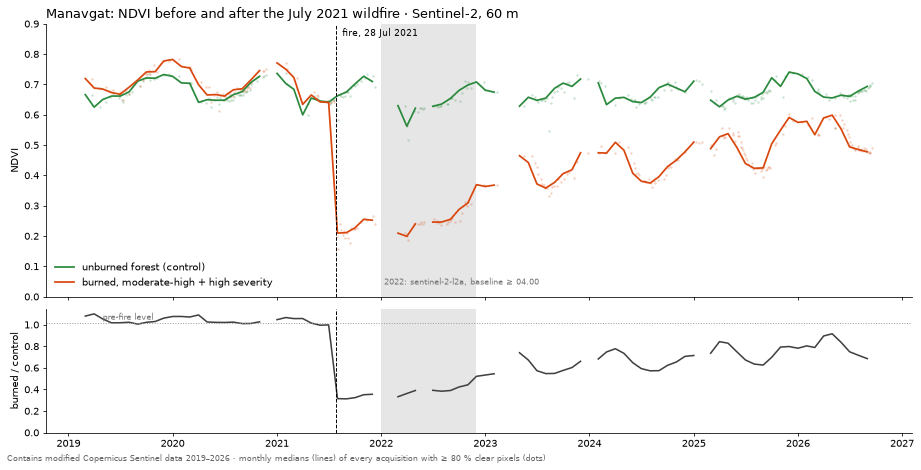

total run time: 273 s


In [10]:
monthly = df.resample("MS").median()

fig, (ax, axr) = plt.subplots(2, 1, figsize=(13, 6.4), sharex=True, height_ratios=[2.2, 1], constrained_layout=True)
for col, color, label in [("control", "#2b8a3e", "unburned forest (control)"), ("burned", "#d9480f", "burned, moderate-high + high severity")]:
    ax.scatter(df.index, df[col], s=6, color=color, alpha=0.25, lw=0)
    ax.plot(monthly.index, monthly[col], color=color, lw=1.8, label=label)
ax.set_ylabel("NDVI")
ax.set_ylim(0, 0.9)
ax.legend(loc="lower left", frameon=False)
ax.set_title("Manavgat: NDVI before and after the July 2021 wildfire · Sentinel-2, 60 m", loc="left", fontsize=13)

axr.plot(monthly.index, monthly.ratio, color="0.25", lw=1.6)
axr.axhline(pre_ratio, color="0.6", ls=":", lw=1)
axr.text(monthly.index[2], pre_ratio + 0.03, "pre-fire level", fontsize=8, color="0.45")
axr.set_ylabel("burned / control")
axr.set_ylim(0, 1.15)

for a in (ax, axr):
    a.axvline(FIRE_START, color="k", ls="--", lw=1)
    a.axvspan(*GAP, color="0.9", lw=0, zorder=0)
    for side in ("top", "right"):
        a.spines[side].set_visible(False)
ax.text(FIRE_START, 0.86, "  fire, 28 Jul 2021", fontsize=9)
ax.text(GAP[0], 0.04, " 2022: sentinel-2-l2a, baseline ≥ 04.00", fontsize=8, color="0.45")
fig.text(0.0, -0.02, "Contains modified Copernicus Sentinel data 2019–2026 · monthly medians (lines) of every acquisition with ≥ 80 % clear pixels (dots)", fontsize=8, color="0.4")
fig.savefig(IMG_DIR / "manavgat_ndvi.png", dpi=130, bbox_inches="tight")
fig.set_dpi(70)
plt.show()
print(f"total run time: {time.time() - T0:.0f} s")

## Reading the results

- **dNBR** captures the fire scar cleanly; the moderate-high and high classes make up the core of it. The low class also picks up some farmland harvested between the two windows, so the "burned" total is an upper bound. An official perimeter (e.g. EFFIS) would be the way to clip it.
- **NDVI** collapses right after the fire and climbs back year after year. The ratio to the control strips out the seasonal cycle and the dry years that affect both areas alike.
- Recovering NDVI is not the same as recovering forest: shrubs and grasses green up long before pines do. NDVI measures *greenness*, not canopy height or biomass.

## Limits and what would come next

- Clip the statistics to the official EFFIS perimeter instead of using the box.
- Split the recovery by severity class, slope and aspect.
- A geospatial foundation model (Prithvi, Clay, TerraMind) could segment the burn scar or classify regrowth. It needs `torch` and, in practice, a GPU, while dNBR answers the same question here and stays explainable.